# Hate speech detection with sarcasm rationales — improved classification **and** explainability
**Google Colab:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. When asked, upload `sarcasm_balanced_9600_full.csv` (or put it in Google Drive / the Colab file panel).

**Goal:** beat the paper (Mamun et al., 2024) on both metric families, measured on the dataset's fixed `paper_split` test set (300 posts).

| Paper (proposed) | Acc 0.7492 | Macro-F1 0.6983 | AUROC 0.8450 | IOU-F1 0.0429 | Token-F1 0.3232 | AUPRC 0.5667 | Comp. −0.0655 | Suff. 0.0546 |
|---|---|---|---|---|---|---|---|---|

**What this notebook changes compared with the paper**
1. **9,000 training posts instead of ~2,600**: the extra 6,418 balanced HateXplain posts (they carry hate rationales but no sarcasm labels; sarcasm losses are simply masked for them).
2. **A dedicated rationale head** trained on the human word-level rationale weights, which gives far better plausibility (token-F1, IOU-F1, AUPRC) than attention or LIME-style occlusion.
3. **Faithfulness training:** each toxic post is also shown to the model as *rationale-only* (the label must survive: lower sufficiency) and *rationale-removed* (the gold class must lose probability: higher comprehensiveness).
4. **Sarcasm as auxiliary tasks:** a sarcasm classifier and a sarcasm-span tagger, trained on the 3,182 sarcasm-annotated posts.
5. **Stronger encoders + ensemble**, layer-wise LR decay, label smoothing, and a **prior-shift correction** (training data is balanced, the test set is not) tuned on the validation set only.
6. Honest statistics: bootstrap confidence intervals and a McNemar test; two baselines (the paper's protocol, and plain BERT on all data) to separate "more data" from "better method".

*Test-set rule:* the test split is used once, at the end. Model selection and tuning use the validation split only.

---
### v6 changes (classification)
The previous run showed that **adding the 6,418 extra HateXplain posts lowered classification**: plain BERT dropped from acc 0.723 / F1 0.646 (2.6k original posts) to acc 0.677 / F1 0.623 (9k posts), and our ensemble did not recover it. The data check explains why:
* 62% of the added posts have only 2-of-3 annotator agreement (45% of the original posts) and on the test set 2/3-agreement posts are classified correctly only 59% of the time vs 81% for 3/3.
* The added posts are 79% Gab (original 53%), and the added Twitter posts contain **no** `normal` examples, so the model can learn "Twitter ⇒ toxic": 22 of 116 normal Twitter test posts were predicted hatespeech.
* Their class mix is 33/32/35 % instead of the natural 37/49/14 %.

**Fixes:** (1) keep only 3/3-agreement extra posts (`EXTRA_AGREE`), optionally only Gab ones (`EXTRA_PLATFORM`); (2) **two-stage training** - after the multi-task training on original + clean-extra posts, fine-tune for 2 epochs on the original posts only, so the classifier ends on the natural distribution (`STAGE2`); (3) prior correction is computed against whatever the last stage was trained on. A `robust` preset averages 4 models to reduce random noise. The test set has 300 posts, so differences below ~3 points are noise - judge by the McNemar test and the confidence interval.

> **AMP stability fix:** Model parameters are kept in FP32. CUDA autocast still performs eligible operations in FP16/BF16, while GradScaler is enabled only for CUDA FP16. This prevents `ValueError: Attempting to unscale FP16 gradients.`
> If you previously ran this notebook, use **Runtime → Restart session**, then run all cells from the top. Existing checkpoints can be loaded; their values are converted to the model's FP32 parameter dtype.

## 1. Setup

In [ ]:
import importlib.util
need = [p for p in ["sentencepiece", "tiktoken", "google.protobuf"] if importlib.util.find_spec(p) is None]
if need:
    %pip install -q sentencepiece tiktoken protobuf
else:
    print("dependencies OK")

dependencies OK


In [ ]:
import os, sys, re, gc, json, glob, random, time, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report)
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "NO GPU - enable one in Runtime settings")

# ----------------------------- configuration -----------------------------
# If DeBERTa ever produces NaN losses under fp16, just delete it from MODELS.
PRESET = "full"    # "quick": 1 encoder (~25-35 min) | "full": 3 encoders (~75-100 min) | "large": roberta-large + deberta-v3-large (~2-3 h). Rough T4 times.
PRESETS = {
    "quick": dict(models=["roberta-base"], seeds=[1], epochs=4),
    "full":  dict(models=["roberta-base", "microsoft/deberta-v3-base", "GroNLP/hateBERT"], seeds=[1], epochs=4),
    "large": dict(models=["roberta-large", "microsoft/deberta-v3-large"], seeds=[1], epochs=3),
    "robust": dict(models=["roberta-base", "GroNLP/hateBERT"], seeds=[1, 2], epochs=4),   # 4 models averaged = less random noise (~2 h on a T4)
}
MODELS, SEEDS, EPOCHS = PRESETS[PRESET]["models"], PRESETS[PRESET]["seeds"], PRESETS[PRESET]["epochs"]
LR_BY_MODEL = {"roberta-large": 1.5e-5, "microsoft/deberta-v3-large": 1.5e-5}

MAXLEN, BS = 160, 16
LR, LLRD, HEAD_LR, WD, WARMUP, CLIP = 3e-5, 0.95, 2e-4, 0.01, 0.1, 1.0
LABEL_SMOOTH = 0.05
W_RAT, W_SARC, W_STAG, W_SUFF, W_COMP = 1.0, 0.2, 0.2, 0.5, 0.3     # loss weights
TOPK, GT_THR = 5, 0.5          # paper protocol: top-5 words; human rationale = words with annotator weight >= 0.5
RUN_ABLATION = False           # True: also trains 4 variants of one encoder to measure what each component adds (+30-40 min)
USE_DRIVE = False              # True: save checkpoints on Google Drive so a disconnect doesn't lose the work
SEED = 42
# ---- v6: classification fixes (see section 2b) ----
EXTRA_AGREE    = "3/3"   # keep only ADDED posts on which all 3 annotators agreed ("2/3" posts are 62% of the added data vs 45% of the original data). None = keep all
EXTRA_PLATFORM = None    # "gab" = drop added Twitter posts (they contain no 'normal' posts, so the model can learn "Twitter => toxic"). None = keep both
STAGE2         = True    # after training on original+clean-extra posts, fine-tune on the ORIGINAL posts only (they have the same distribution as val/test)
STAGE2_EPOCHS, STAGE2_LR = 2, 1e-5

OUT_DIR = "/content/runs" if IN_COLAB else "./runs"
if IN_COLAB and USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive"); OUT_DIR = "/content/drive/MyDrive/sarcasm_hate_runs"
os.makedirs(OUT_DIR, exist_ok=True)

USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
USE_FP16 = USE_AMP and AMP_DTYPE == torch.float16

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
print("preset:", PRESET, "| models:", MODELS, "| seeds:", SEEDS, "| epochs:", EPOCHS)

device: cuda | Tesla T4
preset: full | models: ['roberta-base', 'microsoft/deberta-v3-base', 'GroNLP/hateBERT'] | seeds: [1] | epochs: 4


## 2. Load the dataset
The CSV already contains a fixed split (`paper_split`), word-level **hate-rationale weights** (mean over annotators, aligned with `text.split()`), the **sarcasm mask**, and a `source` column (`original_annotated` = the 3,182 posts with sarcasm labels; `hatexplain_added` = 6,418 extra training posts without them).

In [ ]:
def find_data():
    for p in ["*sarcasm_balanced_9600*.csv", "/content/*sarcasm_balanced_9600*.csv",
              "/content/drive/MyDrive/**/*sarcasm_balanced_9600*.csv", "../input/**/*sarcasm_balanced_9600*.csv"]:
        hits = glob.glob(p, recursive=True)
        if hits: return hits[0]
DATA_PATH = find_data()
if DATA_PATH is None and IN_COLAB:
    from google.colab import files
    print("Upload sarcasm_balanced_9600_full.csv"); DATA_PATH = list(files.upload())[0]
assert DATA_PATH, "CSV not found - upload it (Colab file panel) or put it next to the notebook."
print("using:", DATA_PATH)

LABELS = ["hatespeech", "normal", "offensive"]; L2I = {l: i for i, l in enumerate(LABELS)}; NORMAL_ID = L2I["normal"]
raw = pd.read_csv(DATA_PATH)

def clean_word(w):                     # keeps ONE token per word so rationale weights stay aligned
    return "@user" if w == "<user>" else re.sub(r"^<(\w+)>$", r"\1", w)

df = raw.copy()
df["words"] = df.text.str.split().map(lambda ws: [clean_word(w) for w in ws])
df["y"]     = df.label.map(L2I)
df["hw"]    = df.hate_rationale_weights.map(lambda s: np.array(json.loads(s), dtype=np.float32))
df["rgt"]   = [((w >= GT_THR) if (w >= GT_THR).any() else (w > 0)).astype(int) if y != NORMAL_ID else np.zeros(len(w), int)
               for w, y in zip(df.hw, df.y)]                                    # binary human rationale (toxic posts)
df["sarc"]  = df.sarcasm_label.map({"sarcasm": 1, "non-sarcasm": 0, "unannotated": -1})
df["smask"] = [np.array(json.loads(s), dtype=np.float32) if isinstance(s, str) else None for s in df.sarcasm_rationale_mask]
assert all(len(w) == len(h) for w, h in zip(df.words, df.hw)), "rationale weights are not aligned with words"

tr, va, te = [df[df.paper_split == s].reset_index(drop=True) for s in ["train", "validation", "test"]]
tr_orig = tr[tr.source == "original_annotated"].reset_index(drop=True)          # = the paper's own training data
# ---- v6: keep only CLEAN extra posts (the added HateXplain posts are noisier and differ in platform mix from the test data) ----
_ex = tr[tr.source == "hatexplain_added"]; n_added_all = len(_ex)
if EXTRA_AGREE:    _ex = _ex[_ex.label_agreement == EXTRA_AGREE]
if EXTRA_PLATFORM: _ex = _ex[_ex.platform == EXTRA_PLATFORM]
tr = pd.concat([tr_orig, _ex]).reset_index(drop=True)
print(f"added posts kept: {len(_ex)} of {n_added_all} (agreement={EXTRA_AGREE}, platform={EXTRA_PLATFORM})")
print(f"train={len(tr)} (original {len(tr_orig)} + added {len(tr)-len(tr_orig)}) | val={len(va)} | test={len(te)}")
print("test labels:", te.label.value_counts().to_dict(), "| test toxic posts:", int((te.y != NORMAL_ID).sum()))
print("train labels:", tr.label.value_counts().to_dict(), "(extras are balanced, so train is not natural)  vs  val labels:", va.label.value_counts().to_dict(), "(natural)")
print("sarcasm-annotated train posts:", int((tr.sarc >= 0).sum()), "| sarcastic:", int((tr.sarc == 1).sum()))

Upload sarcasm_balanced_9600_full.csv


Saving sarcasm_balanced_9600_full.csv to sarcasm_balanced_9600_full.csv
using: sarcasm_balanced_9600_full.csv
added posts kept: 2414 of 6418 (agreement=3/3, platform=None)
train=4996 (original 2582 + added 2414) | val=300 | test=300
test labels: {'normal': 146, 'hatespeech': 112, 'offensive': 42} | test toxic posts: 154
train labels: {'hatespeech': 1907, 'normal': 1900, 'offensive': 1189} (extras are balanced, so train is not natural)  vs  val labels: {'normal': 146, 'hatespeech': 113, 'offensive': 41} (natural)
sarcasm-annotated train posts: 2582 | sarcastic: 361


## 3. Metrics and helpers

In [ ]:
def cls_metrics(y, p):
    try: auc = roc_auc_score(y, p, multi_class="ovr", average="macro")
    except ValueError: auc = float("nan")
    return dict(acc=accuracy_score(y, p.argmax(1)), macro_f1=f1_score(y, p.argmax(1), average="macro"), auroc=float(auc))

# ---- plausibility helpers (word level, ERASER style) ----
def top_k_binary(scores, k=TOPK):
    scores = np.asarray(scores, dtype=np.float64); out = np.zeros(len(scores), dtype=int)
    k = min(k, len(scores))
    if k > 0: out[np.argsort(-scores, kind="stable")[:k]] = 1
    return out

def spans(b):
    out, s = [], None
    for i, v in enumerate(b):
        if v and s is None: s = i
        elif not v and s is not None: out.append((s, i)); s = None
    if s is not None: out.append((s, len(b)))
    return out

def _iou(a, b):
    inter = max(0, min(a[1], b[1]) - max(a[0], b[0])); union = (a[1] - a[0]) + (b[1] - b[0]) - inter
    return inter / union if union else 0.0

def iou_f1(pred, gt, thr=0.5):
    ps, gs = spans(pred), spans(gt)
    if not ps or not gs: return 0.0
    p = sum(any(_iou(a, b) > thr for b in gs) for a in ps) / len(ps)
    r = sum(any(_iou(a, b) > thr for a in ps) for b in gs) / len(gs)
    return 0.0 if p + r == 0 else 2 * p * r / (p + r)

def token_f1(pred, gt):
    pred, gt = np.asarray(pred), np.asarray(gt); tp = float((pred * gt).sum())
    if tp == 0: return 0.0
    p, r = tp / pred.sum(), tp / gt.sum(); return 2 * p * r / (p + r)

def select_topk(scores): return top_k_binary(scores, TOPK)
def select_thr(scores, tau):
    r = (np.asarray(scores) >= tau).astype(int)
    return r if r.sum() > 0 else top_k_binary(scores, 1)

# ---- prior-shift correction (train set is balanced, val/test have the natural class mix) ----
def prior(frame): return np.bincount(frame.y, minlength=3) / len(frame)
def shift_probs(p, alpha, shift):
    z = np.log(p + 1e-9) + alpha * shift; z -= z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)
def tune_alpha(pv, yv, train_prior, val_prior):
    shift = np.log(val_prior) - np.log(train_prior); best = (-1, 0.0)
    for a in np.arange(0, 1.01, 0.25):
        m = cls_metrics(yv, shift_probs(pv, a, shift)); s = (m["acc"] + m["macro_f1"]) / 2
        if s > best[0] + 1e-9: best = (s, a)
    return best[1], shift

def free():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

## 4. Tokenisation → word-aligned training items

In [ ]:
_TOK = {}
def get_tok(name):
    if name not in _TOK:
        kw = {"add_prefix_space": True} if "roberta" in name.lower() else {}       # needed for pre-split words
        _TOK[name] = AutoTokenizer.from_pretrained(name, use_fast=True, **kw)
    return _TOK[name]

def tok_words(tok, words):
    enc = tok(list(words), is_split_into_words=True, truncation=True, max_length=MAXLEN)
    return enc["input_ids"], enc.word_ids()

def build_items(frame, tok, variants):
    # one item per post; if `variants`, toxic posts also get a rationale-ONLY and a rationale-REMOVED version
    items = []
    for r in frame.itertuples():
        ids, wids = tok_words(tok, r.words); toxic = r.y != NORMAL_ID
        it = dict(ids=ids, wids=wids, nw=len(r.words), y=int(r.y), sarc=int(r.sarc))
        it["rat"]   = [float(r.hw[w]) if w is not None else 0.0 for w in wids]
        it["rat_m"] = [1.0 if (w is not None and toxic) else 0.0 for w in wids]
        has_tag = r.sarc == 1 and r.smask is not None
        it["stag"]   = [float(r.smask[w]) if (w is not None and has_tag) else 0.0 for w in wids]
        it["stag_m"] = [1.0 if (w is not None and has_tag) else 0.0 for w in wids]
        if variants and toxic:
            keep = [w for w, g in zip(r.words, r.rgt) if g]; rest = [w for w, g in zip(r.words, r.rgt) if not g] or [tok.unk_token]
            it["ids_suff"], it["ids_comp"] = tok_words(tok, keep)[0], tok_words(tok, rest)[0]
        items.append(it)
    return items

def _pad(seqs, fill, dtype):
    L = max(len(s) for s in seqs)
    return torch.tensor([list(s) + [fill] * (L - len(s)) for s in seqs], dtype=dtype)

def make_collate(pad_id):
    def collate(batch):
        out = dict(ids=_pad([b["ids"] for b in batch], pad_id, torch.long),
                   mask=_pad([[1] * len(b["ids"]) for b in batch], 0, torch.long),
                   rat=_pad([b["rat"] for b in batch], 0.0, torch.float), rat_m=_pad([b["rat_m"] for b in batch], 0.0, torch.float),
                   stag=_pad([b["stag"] for b in batch], 0.0, torch.float), stag_m=_pad([b["stag_m"] for b in batch], 0.0, torch.float),
                   y=torch.tensor([b["y"] for b in batch]), sarc=torch.tensor([b["sarc"] for b in batch]))
        ax, ay, ac = [], [], []
        for b in batch:
            if "ids_suff" in b:
                ax += [b["ids_suff"], b["ids_comp"]]; ay += [b["y"], b["y"]]; ac += [0, 1]
        if ax:
            out.update(ax=_pad(ax, pad_id, torch.long), am=_pad([[1] * len(a) for a in ax], 0, torch.long),
                       ay=torch.tensor(ay), ac=torch.tensor(ac))
        return out
    return collate

## 5. Model
One encoder, four heads: **(1)** hate / normal / offensive, **(2)** word-level *hate rationale*, **(3)** is-sarcastic, **(4)** sarcasm-span tagger. The classifier reads `[CLS]` + mean-pooled tokens.

In [ ]:
class MTModel(nn.Module):
    def __init__(self, name, dropout=0.1):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        h = self.enc.config.hidden_size
        self.drop = nn.Dropout(dropout)
        self.cls_head, self.sarc_head = nn.Linear(2 * h, 3), nn.Linear(2 * h, 2)
        self.rat_head  = nn.Sequential(nn.Linear(h, h), nn.GELU(), nn.Dropout(dropout), nn.Linear(h, 1))
        self.stag_head = nn.Linear(h, 1)
        self.pad_id = 0
    def head_params(self):
        return [p for n, p in self.named_parameters() if not n.startswith("enc.")]
    def _pool(self, hs, mask):
        m = mask.unsqueeze(-1).to(hs.dtype)
        return self.drop(torch.cat([hs[:, 0], (hs * m).sum(1) / m.sum(1).clamp_min(1)], -1))
    def forward(self, ids, mask):
        hs = self.enc(input_ids=ids, attention_mask=mask).last_hidden_state
        z = self._pool(hs, mask); hd = self.drop(hs)
        return self.cls_head(z), self.sarc_head(z), self.rat_head(hd).squeeze(-1), self.stag_head(hd).squeeze(-1)
    def forward_cls(self, ids, mask):                       # used for the rationale-only / rationale-removed inputs
        hs = self.enc(input_ids=ids, attention_mask=mask).last_hidden_state
        return self.cls_head(self._pool(hs, mask))

def build_optimizer(model, lr, llrd, head_lr, wd):
    n = model.enc.config.num_hidden_layers; groups = {}
    for name, p in model.enc.named_parameters():
        m = re.search(r"encoder\.layer\.(\d+)\.", name)
        depth = int(m.group(1)) + 1 if m else (0 if "embeddings" in name else n)
        no_wd = name.endswith("bias") or "LayerNorm" in name or "layer_norm" in name
        groups.setdefault((lr * llrd ** (n - depth), 0.0 if no_wd else wd), []).append(p)
    pg = [dict(params=v, lr=k[0], weight_decay=k[1]) for k, v in groups.items()]
    pg.append(dict(params=model.head_params(), lr=head_lr, weight_decay=wd))
    return torch.optim.AdamW(pg)

def compute_loss(model, b, cfg):
    lc, ls_, lr_, lt = model(b["ids"], b["mask"])
    loss = F.cross_entropy(lc.float(), b["y"], label_smoothing=cfg["ls"])
    if cfg["rat"]:                                           # (2) learn WHICH words are hateful
        bce = F.binary_cross_entropy_with_logits(lr_.float(), b["rat"], reduction="none")
        w = b["rat_m"] * (1.0 + (b["rat"] > 0).float())      # rationale words are the minority -> up-weight
        loss = loss + W_RAT * (bce * w).sum() / w.sum().clamp_min(1.0)
    if cfg["sarc"]:                                          # (3)+(4) sarcasm tasks, only where annotated
        m = b["sarc"] >= 0
        if m.any(): loss = loss + W_SARC * F.cross_entropy(ls_[m].float(), b["sarc"][m])
        if b["stag_m"].sum() > 0:
            bce = F.binary_cross_entropy_with_logits(lt.float(), b["stag"], reduction="none")
            loss = loss + W_STAG * (bce * b["stag_m"]).sum() / b["stag_m"].sum()
    if cfg["faith"] and "ax" in b:                           # faithfulness: sufficiency + comprehensiveness training
        la = model.forward_cls(b["ax"], b["am"]).float(); s = b["ac"] == 0; c = ~s
        if s.any(): loss = loss + W_SUFF * F.cross_entropy(la[s], b["ay"][s], label_smoothing=cfg["ls"])
        if c.any():
            py = F.softmax(la[c], -1).gather(1, b["ay"][c][:, None]).squeeze(1)
            loss = loss + W_COMP * (-torch.log((1 - py).clamp_min(1e-4))).mean()    # unlikelihood: gold class must drop
    return loss

@torch.no_grad()
def run_model(model, items, bs=64):
    # -> class probs, sarcasm prob, and word-level rationale scores (mean sigmoid over each word's pieces)
    model.to(DEVICE).eval(); col = make_collate(model.pad_id); P, S, WS = [], [], []
    for i in range(0, len(items), bs):
        chunk = items[i:i + bs]; b = {k: v.to(DEVICE) for k, v in col(chunk).items()}
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            lc, ls_, lr_, _ = model(b["ids"], b["mask"])
        P.append(F.softmax(lc.float(), -1).cpu().numpy()); S.append(F.softmax(ls_.float(), -1)[:, 1].cpu().numpy())
        sig = torch.sigmoid(lr_.float()).cpu().numpy()
        for k, it in enumerate(chunk):
            sc, ct = np.zeros(it["nw"]), np.zeros(it["nw"])
            for pos, w in enumerate(it["wids"]):
                if w is not None: sc[w] += sig[k, pos]; ct[w] += 1
            WS.append(sc / np.maximum(ct, 1))
    return dict(probs=np.concatenate(P), sarc=np.concatenate(S), ws=WS)

def train_one(name, tr_items, va_items, va_y, va_gt, cfg, seed, verbose=True, init_state=None):
    set_seed(seed); tok = get_tok(name)
    model = MTModel(name).to(DEVICE).float()  # Keep trainable parameters in FP32; AMP handles lower precision inside forward passes
    model.pad_id = tok.pad_token_id
    if init_state is not None: model.load_state_dict(init_state)          # stage-2 fine-tuning starts from the stage-1 weights
    assert all(p.dtype == torch.float32 for p in model.parameters()), "Expected FP32 model parameters before AMP training."
    lr = cfg["lr"] or LR_BY_MODEL.get(name, LR)
    opt = build_optimizer(model, lr, cfg["llrd"], cfg["head_lr"], WD)
    loader = DataLoader(tr_items, batch_size=BS, shuffle=True, collate_fn=make_collate(model.pad_id))
    total = len(loader) * cfg["epochs"]; sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16) if DEVICE.type == "cuda" else torch.amp.GradScaler("cpu", enabled=False)
    toxic_va = np.where(va_y != NORMAL_ID)[0]
    best, best_state = -1.0, None
    for ep in range(cfg["epochs"]):
        model.train(); tot, nb = 0.0, 0
        for b in loader:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                loss = compute_loss(model, b, cfg)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            if USE_FP16:
                scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CLIP); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); nb += 1
        out = run_model(model, va_items); f1 = f1_score(va_y, out["probs"].argmax(1), average="macro"); score, tf = f1, None
        if cfg["rat"]:                                       # model selection: classification + rationale quality (validation only)
            tf = float(np.mean([token_f1(top_k_binary(out["ws"][i]), va_gt[i]) for i in toxic_va])); score = f1 + tf
        if verbose: print(f"  epoch {ep+1}/{cfg['epochs']} | train loss {tot/nb:.3f} | val macro-F1 {f1:.4f}" + (f" | val token-F1 {tf:.4f}" if tf is not None else ""))
        if score > best: best, best_state = score, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, best_state

## 6. Explanation + faithfulness evaluation (ERASER protocol, as in the paper)
* **Plausibility** vs the human rationale: token-F1, IOU-F1 (partial span match, IOU > 0.5), AUPRC over the soft scores.
* **Faithfulness**, on the predicted class *j*: comprehensiveness = p(x)ⱼ − p(x without rationale)ⱼ (**higher** is better); sufficiency = p(x)ⱼ − p(rationale only)ⱼ (**lower** is better).
* Evaluated on the toxic test posts, as in HateXplain. Words are *deleted*, not masked. Explainers: **occlusion** (model-agnostic, like LIME: drop each word and watch the prediction) and the **rationale head**.

In [ ]:
@torch.no_grad()
def ens_predict(models, wordlists, bs=128):
    # mean class probabilities of an ensemble [(name, model), ...] on arbitrary word lists (models are moved to GPU one at a time)
    acc = None
    for name, model in models:
        tok = get_tok(name); model.to(DEVICE).eval()
        ids_all = [tok_words(tok, w if len(w) else [tok.unk_token])[0] for w in wordlists]
        order = np.argsort([len(x) for x in ids_all]); probs = np.zeros((len(ids_all), 3))
        for i in range(0, len(order), bs):
            idx = order[i:i + bs]; seqs = [ids_all[j] for j in idx]
            ids = _pad(seqs, tok.pad_token_id, torch.long).to(DEVICE); mask = _pad([[1] * len(s) for s in seqs], 0, torch.long).to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                lc = model.forward_cls(ids, mask)
            probs[idx] = F.softmax(lc.float(), -1).cpu().numpy()
        acc = probs if acc is None else acc + probs; model.cpu()
    free()
    return acc / len(models)

def occlusion_scores(models, recs, p_full):
    variants, owner = [], []
    for k, r in enumerate(recs):
        for i in range(len(r["words"])):
            variants.append(r["words"][:i] + r["words"][i + 1:]); owner.append((k, i))
    P = ens_predict(models, variants); j = p_full.argmax(1)
    scores = [np.zeros(len(r["words"])) for r in recs]
    for (k, i), p in zip(owner, P): scores[k][i] = p_full[k][j[k]] - p[j[k]]
    return scores

def explain_report(models, recs, scores, select_fn, p_full):
    sel = [select_fn(s) for s in scores]
    tf = [token_f1(s, r["gt"]) for s, r in zip(sel, recs)]; io = [iou_f1(s, r["gt"]) for s, r in zip(sel, recs)]
    ap = [average_precision_score(r["gt"], sc) for sc, r in zip(scores, recs) if 0 < r["gt"].sum() < len(r["gt"])]
    keep = [[w for w, s in zip(r["words"], se) if s] for r, se in zip(recs, sel)]
    drop = [[w for w, s in zip(r["words"], se) if not s] for r, se in zip(recs, sel)]
    P = ens_predict(models, keep + drop); n = len(recs); j = p_full.argmax(1); ix = np.arange(n)
    return dict(iou_f1=np.mean(io), token_f1=np.mean(tf), auprc=np.mean(ap),
                comprehensiveness=float(np.mean(p_full[ix, j] - P[n:][ix, j])), sufficiency=float(np.mean(p_full[ix, j] - P[:n][ix, j])))

## 7. Baselines (same test set)
* **B0 — paper protocol:** plain `bert-base-uncased`, `[CLS]` head only, trained on the 2,582 original posts.
* **B1 — plain BERT, all 9,000 posts:** isolates the effect of *more data* from the effect of the *method*.

In [ ]:
CFG_PLAIN = dict(rat=False, sarc=False, faith=False, llrd=1.0, ls=0.0, lr=2e-5, head_lr=2e-5, epochs=5)
CFG_OURS  = dict(rat=True,  sarc=True,  faith=True,  llrd=LLRD, ls=LABEL_SMOOTH, lr=None, head_lr=HEAD_LR, epochs=EPOCHS)
va_y, te_y = va.y.values, te.y.values
va_tox, te_tox = np.where(va_y != NORMAL_ID)[0], np.where(te_y != NORMAL_ID)[0]
SYS = {}

def fit(label, name, frame, cfg, seed, variants, init_state=None, tag_extra=""):
    # train (or reload a saved checkpoint), then collect val/test outputs and park the model on the CPU
    tag = re.sub(r"[^A-Za-z0-9]+", "_", f"{label}_{name}_s{seed}_r{int(cfg['rat'])}s{int(cfg['sarc'])}f{int(cfg['faith'])}_e{cfg['epochs']}_n{len(frame)}{tag_extra}")
    tok = get_tok(name); path = f"{OUT_DIR}/{tag}.pt"
    va_items, te_items = build_items(va, tok, False), build_items(te, tok, False)
    if os.path.exists(path):
        model = MTModel(name); model.load_state_dict(torch.load(path, map_location="cpu")); model.pad_id = tok.pad_token_id
        print(f"[{label}] {name} seed {seed}: loaded checkpoint")
    else:
        print(f"[{label}] training {name} seed {seed} on {len(frame)} posts"); t0 = time.time()
        model, state = train_one(name, build_items(frame, tok, variants), va_items, va_y, list(va.rgt), cfg, seed, init_state=init_state)
        torch.save(state, path); print(f"  done in {time.time()-t0:.0f}s")
    ov, ot = run_model(model, va_items), run_model(model, te_items); model.cpu(); free()
    return dict(name=name, model=model, pv=ov["probs"], pt=ot["probs"], ws_va=ov["ws"], ws_te=ot["ws"], sarc_te=ot["sarc"])

def make_system(members, train_prior):
    return dict(models=[(m["name"], m["model"]) for m in members], pv=np.mean([m["pv"] for m in members], 0),
                pt=np.mean([m["pt"] for m in members], 0), ws_va=[np.mean(x, 0) for x in zip(*[m["ws_va"] for m in members])],
                ws_te=[np.mean(x, 0) for x in zip(*[m["ws_te"] for m in members])], train_prior=train_prior)

t0 = time.time()
SYS["B0 BERT, paper protocol (2.6k posts)"] = make_system([fit("B0", "bert-base-uncased", tr_orig, CFG_PLAIN, 1, False)], prior(tr_orig))
SYS["B1 BERT, orig + clean extras"]                = make_system([fit("B1", "bert-base-uncased", tr, {**CFG_PLAIN, "epochs": 3}, 1, False)], prior(tr))
for k, s in SYS.items(): print(k, {a: round(b, 4) for a, b in cls_metrics(te_y, s["pt"]).items()})
print(f"baselines: {time.time()-t0:.0f}s")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[B0] training bert-base-uncased seed 1 on 2582 posts


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (3 outputs left out)

  epoch 1/5 | train loss 0.881 | val macro-F1 0.5055
  epoch 2/5 | train loss 0.612 | val macro-F1 0.5867
  epoch 3/5 | train loss 0.429 | val macro-F1 0.6194
  epoch 4/5 | train loss 0.270 | val macro-F1 0.6372
  epoch 5/5 | train loss 0.169 | val macro-F1 0.6249
  done in 96s
[B1] training bert-base-uncased seed 1 on 4996 posts


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  epoch 1/3 | train loss 0.839 | val macro-F1 0.6279
  epoch 2/3 | train loss 0.563 | val macro-F1 0.6722
  epoch 3/3 | train loss 0.378 | val macro-F1 0.6437
  done in 98s
B0 BERT, paper protocol (2.6k posts) {'acc': 0.7233, 'macro_f1': 0.6463, 'auroc': 0.8316}
B1 BERT, orig + clean extras {'acc': 0.7433, 'macro_f1': 0.67, 'auroc': 0.8578}
baselines: 200s


## 8. Our model — multi-task + faithfulness training, ensemble of encoders
Training data is the full 9,000-post set. Per epoch the model is scored on the **validation** split (macro-F1 + rationale token-F1) and the best epoch is kept.

In [ ]:
t0, members, members2 = time.time(), [], []
CFG_S2 = {**CFG_OURS, "epochs": STAGE2_EPOCHS, "lr": STAGE2_LR, "head_lr": STAGE2_LR * 5}
for name in MODELS:
    for seed in SEEDS:
        members.append(fit("OURS", name, tr, CFG_OURS, seed, True))
        print(f"   -> stage 1 {name} s{seed}: val macro-F1 {cls_metrics(va_y, members[-1]['pv'])['macro_f1']:.4f} | test", {a: round(b, 4) for a, b in cls_metrics(te_y, members[-1]['pt']).items()})
        if STAGE2:      # fine-tune on the ORIGINAL posts only (natural class mix, same sources as val/test)
            init = {k: v.clone() for k, v in members[-1]["model"].state_dict().items()}
            members2.append(fit("OURS-S2", name, tr_orig, CFG_S2, seed, True, init_state=init, tag_extra="_stage2"))
            print(f"   -> stage 2 {name} s{seed}: val macro-F1 {cls_metrics(va_y, members2[-1]['pv'])['macro_f1']:.4f} | test", {a: round(b, 4) for a, b in cls_metrics(te_y, members2[-1]['pt']).items()})
if STAGE2:
    SYS["OURS stage 1 (before fine-tuning)"] = make_system(members, prior(tr))
    SYS["OURS ensemble"] = make_system(members2, prior(tr_orig))
else:
    SYS["OURS ensemble"] = make_system(members, prior(tr))
print(f"training total: {time.time()-t0:.0f}s")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[OURS] training roberta-base seed 1 on 4996 posts


... (32 outputs left out)

  epoch 1/4 | train loss 2.021 | val macro-F1 0.6510 | val token-F1 0.5089
  epoch 2/4 | train loss 1.576 | val macro-F1 0.6981 | val token-F1 0.5118
  epoch 3/4 | train loss 1.338 | val macro-F1 0.6677 | val token-F1 0.5158
  epoch 4/4 | train loss 1.195 | val macro-F1 0.6694 | val token-F1 0.5180
  done in 283s
   -> stage 1 GroNLP/hateBERT s1: val macro-F1 0.6981 | test {'acc': 0.73, 'macro_f1': 0.6525, 'auroc': 0.8653}
[OURS-S2] training GroNLP/hateBERT seed 1 on 2582 posts


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: GroNLP/hateBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  epoch 1/2 | train loss 1.381 | val macro-F1 0.6873 | val token-F1 0.5154
  epoch 2/2 | train loss 1.276 | val macro-F1 0.6946 | val token-F1 0.5157
  done in 123s
   -> stage 2 GroNLP/hateBERT s1: val macro-F1 0.6946 | test {'acc': 0.73, 'macro_f1': 0.6452, 'auroc': 0.8638}
training total: 1321s


## 9. Classification results
Prior-shift correction: the training data is balanced but the validation/test posts follow the natural class mix, so predicted probabilities are re-weighted by `(val prior / train prior)^α`. **α is chosen on the validation set only.**

In [ ]:
PAPER_CLS = {"Paper baseline (their test)": dict(acc=0.7425, macro_f1=0.6883, auroc=0.8264),
             "Paper proposed (their test)": dict(acc=0.7492, macro_f1=0.6983, auroc=0.8450)}
val_prior = prior(va); rows, FINAL = dict(PAPER_CLS), {}
for k, s in SYS.items():
    alpha, shift = tune_alpha(s["pv"], va_y, s["train_prior"], val_prior)
    s["alpha"], s["pt_adj"] = alpha, shift_probs(s["pt"], alpha, shift)
    rows[f"{k} (raw)"] = cls_metrics(te_y, s["pt"])
    if alpha > 0: rows[f"{k} + prior correction (alpha={alpha:.2f})"] = cls_metrics(te_y, s["pt_adj"])
    FINAL[k] = s["pt_adj"]
tab_cls = pd.DataFrame(rows).T.round(4); print(tab_cls.to_string())

                                                                      acc  macro_f1   auroc
Paper baseline (their test)                                        0.7425    0.6883  0.8264
Paper proposed (their test)                                        0.7492    0.6983  0.8450
B0 BERT, paper protocol (2.6k posts) (raw)                         0.7233    0.6463  0.8316
B1 BERT, orig + clean extras (raw)                                 0.7433    0.6700  0.8578
OURS stage 1 (before fine-tuning) (raw)                            0.7500    0.6777  0.8665
OURS stage 1 (before fine-tuning) + prior correction (alpha=0.75)  0.7700    0.6886  0.8672
OURS ensemble (raw)                                                0.7633    0.6741  0.8737
OURS ensemble + prior correction (alpha=0.50)                      0.7633    0.6741  0.8737


OURS final: {'acc': 0.7633, 'macro_f1': 0.6741, 'auroc': 0.8737} 

              precision    recall  f1-score   support

  hatespeech      0.765     0.812     0.788       112
      normal      0.837     0.842     0.840       146
   offensive      0.441     0.357     0.395        42

    accuracy                          0.763       300
   macro avg      0.681     0.671     0.674       300
weighted avg      0.754     0.763     0.758       300

accuracy 95% CI [0.713, 0.810] | macro-F1 95% CI [0.615, 0.734]
vs B0 BERT, paper protocol (2.6k posts): ours-only correct=33, other-only correct=21, McNemar p=0.1337
vs B1 BERT, orig + clean extras: ours-only correct=17, other-only correct=11, McNemar p=0.3449

accuracy on SARCASTIC test posts (n=43): ours=0.698  B0=0.605 | non-sarcastic: ours=0.774  B0=0.743


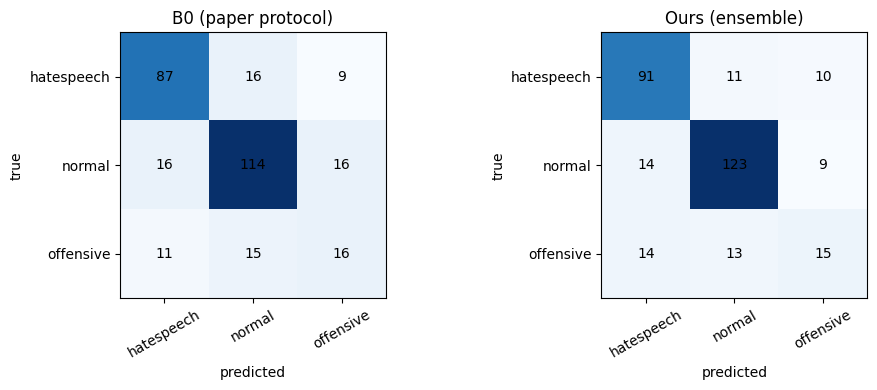

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import binomtest
final = FINAL["OURS ensemble"]; pred_f = final.argmax(1)
print("OURS final:", {k: round(v, 4) for k, v in cls_metrics(te_y, final).items()}, "\n")
print(classification_report(te_y, pred_f, target_names=LABELS, digits=3))

rng = np.random.default_rng(0); A, M = [], []
for _ in range(2000):
    i = rng.integers(0, len(te_y), len(te_y)); A.append((pred_f[i] == te_y[i]).mean()); M.append(f1_score(te_y[i], pred_f[i], average="macro"))
print(f"accuracy 95% CI [{np.percentile(A,2.5):.3f}, {np.percentile(A,97.5):.3f}] | macro-F1 95% CI [{np.percentile(M,2.5):.3f}, {np.percentile(M,97.5):.3f}]")

for other in ["B0 BERT, paper protocol (2.6k posts)", "B1 BERT, orig + clean extras"]:
    po = FINAL[other].argmax(1); cf, co = pred_f == te_y, po == te_y
    a, b = int((cf & ~co).sum()), int((co & ~cf).sum())
    print(f"vs {other}: ours-only correct={a}, other-only correct={b}, McNemar p={binomtest(min(a,b), a+b, 0.5).pvalue if a+b else 1.0:.4f}")

sm = (te.sarc == 1).values; cf = pred_f == te_y; cb = FINAL["B0 BERT, paper protocol (2.6k posts)"].argmax(1) == te_y
print(f"\naccuracy on SARCASTIC test posts (n={sm.sum()}): ours={cf[sm].mean():.3f}  B0={cb[sm].mean():.3f} | non-sarcastic: ours={cf[~sm].mean():.3f}  B0={cb[~sm].mean():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (nm, pr) in zip(ax, [("B0 (paper protocol)", FINAL["B0 BERT, paper protocol (2.6k posts)"].argmax(1)), ("Ours (ensemble)", pred_f)]):
    cm = confusion_matrix(te_y, pr); a.imshow(cm, cmap="Blues"); a.set_xticks(range(3)); a.set_yticks(range(3))
    a.set_xticklabels(LABELS, rotation=30); a.set_yticklabels(LABELS); a.set_title(nm); a.set_xlabel("predicted"); a.set_ylabel("true")
    for i in range(3):
        for j in range(3): a.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.show()

## 10. Explainability results (toxic test posts)
Every system is scored with the same ERASER protocol. For the baselines the only available explainer is occlusion. For our model we report **both** explainers, so the improvement from the rationale head can be separated from the improvement of the classifier itself. "Rationale head, threshold" picks the words with score ≥ τ, where **τ is tuned on the validation set under a length budget** (at most 1.25× the human rationale length); contiguous spans are what IOU-F1 rewards. The two **Reference** rows (random top-5, select all words) show what a clueless explainer scores, so you can judge the real gains against them.

In [ ]:
recs = [dict(words=te.words[i], gt=te.rgt[i]) for i in te_tox]
PAPER_EX = {"Paper baseline (LIME, top-5)": dict(iou_f1=0.0577, token_f1=0.2799, auprc=0.3884, comprehensiveness=0.1789, sufficiency=0.1363),
            "Paper proposed (LIME, top-5)": dict(iou_f1=0.0429, token_f1=0.3232, auprc=0.5667, comprehensiveness=-0.0655, sufficiency=0.0546)}
ex = dict(PAPER_EX); t0 = time.time()

for k in ["B0 BERT, paper protocol (2.6k posts)", "B1 BERT, orig + clean extras"]:
    s = SYS[k]; p_full = ens_predict(s["models"], [r["words"] for r in recs])
    ex[f"{k} | occlusion, top-5"] = explain_report(s["models"], recs, occlusion_scores(s["models"], recs, p_full), select_topk, p_full)

S = SYS["OURS ensemble"]; p_full = ens_predict(S["models"], [r["words"] for r in recs])
ex["OURS | occlusion, top-5"] = explain_report(S["models"], recs, occlusion_scores(S["models"], recs, p_full), select_topk, p_full)
sc_te = [S["ws_te"][i] for i in te_tox]
ex["OURS | rationale head, top-5"] = explain_report(S["models"], recs, sc_te, select_topk, p_full)

# threshold tuned on VALIDATION toxic posts only, under a length budget (otherwise "select every word" would win token-F1)
taus = np.arange(0.10, 0.91, 0.05); frac_gt = float(np.mean([va.rgt[i].mean() for i in va_tox])); budget = 1.25 * frac_gt
cand = []
for t in taus:
    sel = [select_thr(S["ws_va"][i], t) for i in va_tox]
    cand.append((float(t), float(np.mean([token_f1(se, va.rgt[i]) for se, i in zip(sel, va_tox)])), float(np.mean([se.mean() for se in sel]))))
ok = [c for c in cand if c[2] <= budget] or [max(cand, key=lambda c: c[0])]
TAU, tf_best, fr_best = max(ok, key=lambda c: c[1])
print(f"tau (val) = {TAU:.2f} | val token-F1 = {tf_best:.3f} | selected {fr_best:.0%} of words (human {frac_gt:.0%}, budget {budget:.0%})")
ex[f"OURS | rationale head, threshold {TAU:.2f}"] = explain_report(S["models"], recs, sc_te, lambda s: select_thr(s, TAU), p_full)

# reference rows: trivial explainers, so over-selection cannot be mistaken for a good explanation
rng = np.random.default_rng(0)
ex["Reference | random top-5"]      = explain_report(S["models"], recs, [rng.random(len(r["words"])) for r in recs], select_topk, p_full)
ex["Reference | select ALL words"]  = explain_report(S["models"], recs, [np.ones(len(r["words"])) for r in recs], lambda s: np.ones(len(s), int), p_full)

tab_ex = pd.DataFrame(ex).T[["iou_f1", "token_f1", "auprc", "comprehensiveness", "sufficiency"]].round(4)
tab_ex.columns = ["IOU-F1 ↑", "Token-F1 ↑", "AUPRC ↑", "Comprehens. ↑", "Sufficiency ↓"]
print(tab_ex.to_string()); print(f"({time.time()-t0:.0f}s)")

In [ ]:
# qualitative check: human vs model rationale (first toxic test posts)
def mark(words, sel): return " ".join(f"[{w}]" if s else w for w, s in zip(words, sel))
for i in range(5):
    r = recs[i]; sel = select_thr(sc_te[i], TAU)
    print(f"true={LABELS[te_y[te_tox[i]]]:<10} pred={LABELS[final[te_tox[i]].argmax()]:<10}")
    print("  HUMAN:", mark(r["words"], r["gt"])); print("  MODEL:", mark(r["words"], sel), "\n")

## 11. Save everything

In [ ]:
tab_cls.to_csv(f"{OUT_DIR}/classification_results.csv"); tab_ex.to_csv(f"{OUT_DIR}/explainability_results.csv")
out = te[["post_id", "text", "label", "sarcasm_label"]].copy(); out["pred"] = [LABELS[i] for i in pred_f]
for i, l in enumerate(LABELS): out[f"p_{l}"] = final[:, i].round(4)
out.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)
print("saved to", OUT_DIR)
if IN_COLAB:
    from google.colab import files
    for f in ["classification_results.csv", "explainability_results.csv", "test_predictions.csv"]: files.download(f"{OUT_DIR}/{f}")

## 12. (Optional) Ablation — what does each component add, and does sarcasm help?
Same encoder (`MODELS[0]`, first seed), four variants, evaluated on the test set for reporting only (nothing above was selected with it). One seed means differences below roughly 1.5 points are noise. Set `RUN_ABLATION = True` in the config cell to run it.

In [ ]:
if RUN_ABLATION:
    name, seed = MODELS[0], SEEDS[0]; tok = get_tok(name); abl = {}
    variants = {"1 classifier only (+ tricks)":        dict(rat=False, sarc=False, faith=False),
                "2 + rationale head":                  dict(rat=True,  sarc=False, faith=False),
                "3 + sarcasm tasks":                   dict(rat=True,  sarc=True,  faith=False),
                "4 + faithfulness training (= OURS)":  dict(rat=True,  sarc=True,  faith=True)}
    for vn, flags in variants.items():
        m = fit("ABL", name, tr, {**CFG_OURS, **flags}, seed, flags["faith"]); mods = [(name, m["model"])]
        pf = ens_predict(mods, [r["words"] for r in recs])
        sc = [m["ws_te"][i] for i in te_tox] if flags["rat"] else occlusion_scores(mods, recs, pf)
        thr = (lambda s: select_thr(s, TAU)) if flags["rat"] else select_topk
        abl[vn] = {**{k: v for k, v in cls_metrics(te_y, m["pt"]).items() if k != "auroc"}, **explain_report(mods, recs, sc, thr, pf)}
    print(pd.DataFrame(abl).T.round(4).to_string())
    print("\n(variant 1 is explained by occlusion, variants 2-4 by their rationale head)")
else:
    print("ablation skipped (RUN_ABLATION = False)")